# Exercise 2


In [26]:
import autograd.numpy as np

In [35]:
csvname = 'multiple_sine_waves.csv'
data = np.loadtxt(csvname,delimiter=',')
x = data[:2,:]
y = data[2:,:]

In [40]:
def feature_transforms(x,w):
    a = w[0] + np.dot(x.T,w[1:])
    return np.sin(a).reshape(1, -1)

def model(x,w):    
    # feature transformation 
    f = feature_transforms(x,w[0])
    
    # compute linear combination and return
    a = w[1][0] + np.dot(f.T,w[1][1:])
    return a.T

In [37]:
from autograd import grad 

def gradient_descent(g, alpha, max_its, w):
    gradient = grad(g)

    weight_history = [w]
    cost_history = [g(w)]

    for k in range(max_its):
        grad_eval = gradient(w)

        # update each block separately
        w = [
            w[i] - alpha * grad_eval[i]
            for i in range(len(w))
        ]

        weight_history.append(w)
        cost_history.append(g(w))

    return cost_history, weight_history

In [38]:
def least_squares(w):
	# compute the least squares cost
	cost = np.sum((model(x, w) - y) ** 2)
	return cost / float(y.size)

In [ ]:
# parameter settings
max_its = 2000
alpha = 0.01

# gradient descent call
w0 = [
    np.array([-0.1, 0.1, 0.1]),   
    np.array([0.0, 0.1])         
]
cost_history, weight_history = gradient_descent(least_squares, alpha, max_its, w0)

In [ ]:
# optimal parametters
wopt = weight_history[-1]
wopt

[array([-0.10527249,  0.05363957,  0.0779151 ]),
 array([-0.05612088, -0.00544886])]

The linear parameters are: [-0.10527249,  0.05363957,  0.0779151 ]
The non linear parameters are: [-0.05612088, -0.00544886]

yhat ​= −0.0561 − 0.00545⋅sin(−0.1053 + 0.0536.x1 ​+ 0.0779.x2​)

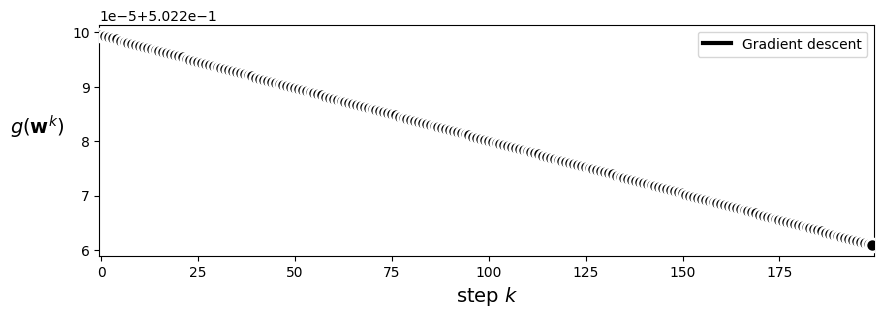

In [51]:
# cost_history plot
from MLRPlotting import static_plotter
# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history[1800:2000]],start=0,points=True,labels=[r'Gradient descent'])